# Prototype Conformer Tabular Medical Check-up

**Tujuan notebook:** mencoba pipeline Conformer pada **dataset yang benar** untuk demo/prototype.

> Dataset ini masih dataset lama untuk eksperimen. Target 4 kelas digunakan hanya untuk mencoba pipeline.

Target:
- `0` = Sehat / Tidak Ada Indikasi
- `1` = Jantung dan Pembuluh Darah
- `2` = Spes. Penyakit Dalam
- `3` = Spes. Paru-Paru

Flow notebook:

```text
NOTE 2.1  Load & Audit
      ↓
NOTE 2.2  Define Feature & Target
      ↓
NOTE 2.3  Train/Validation/Test Split
      ↓
NOTE 2.4  Scaling
      ↓
NOTE 2.5  Tabular Tokenization
      ↓
NOTE 2.6  Conformer Block
      ↓
NOTE 2.7  Forward Pass
      ↓
NOTE 2.8  Training
      ↓
NOTE 2.9  Evaluation
      ↓
NOTE 2.10 Single Patient Prediction
```

Notebook ini dibuat lebih stabil daripada prototype sebelumnya: dataset sudah numerik/bersih, preprocessing tidak melakukan mapping kategorikal ulang, model menggunakan **pre-norm + residual yang stabil**, gradient clipping, dan learning rate konservatif.

## 1. Import Library & Load Dataset

In [ ]:
import os
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch :", torch.__version__)
print("Device  :", device)


PyTorch : 2.11.0+cpu
Device  : cpu


In [ ]:
#DATA_PATH = "merge_DocLab_hybrid.csv"
DATA_PATH = "merge_DocLab_balanced.csv"

df = pd.read_csv(DATA_PATH)

print("Shape:", df.shape)
df.head(5)

Shape: (7100, 14)


,JENIS_KELAMIN,UMUR_TAHUN,cholesterol total,creatinin,fbs,rbs,hgb,lymfosit%,mch,mchc,mcv,ureum,wbc,NM_UNIT
0,1,61.0,169.98,0.40,115.3,220.4,11.0,14.4,25.8,32.4,79.6,100.0,9.9,0
1,0,59.0,111.00,1.68,70.0,193.4,12.0,26.9,25.9,34.0,76.2,100.0,14.7,0
2,1,40.0,166.59,0.78,117.2,70.0,13.1,12.6,28.7,32.8,88.1,46.0,11.9,0
3,1,69.0,218.78,2.50,103.7,161.8,9.4,30.3,20.8,29.7,69.8,10.0,5.8,0
4,1,45.0,222.84,1.22,79.3,217.3,8.2,20.5,26.6,37.0,105.0,100.0,15.9,0


In [ ]:
print("Data types:")
df.dtypes

print("\nMissing values:")
df.isna().sum()

print("\nDuplicated rows:", df.duplicated().sum())

print("\nTarget distribution:")
df["NM_UNIT"].value_counts().sort_index()

Data types:

Missing values:

Duplicated rows: 0

Target distribution:


,count
NM_UNIT,
0,2100
1,1500
2,2000
3,1500


## 2. Target & Feature Definition

In [ ]:
TARGET_COL = "NM_UNIT"

TARGET_NAMES = {
    0: "Sehat / Tidak Ada Indikasi",
    1: "Jantung dan Pembuluh Darah",
    2: "Spes. Penyakit Dalam",
    3: "Spes. Paru-Paru",
}

# Untuk prototype, gunakan urutan kolom dataset sebagai fixed feature ordering.
FEATURE_ORDER = [
    "JENIS_KELAMIN",
    "UMUR_TAHUN",
    "cholesterol total",
    "creatinin",
    "fbs",
    "rbs",
    "hgb",
    "lymfosit%",
    "mch",
    "mchc",
    "mcv",
    "ureum",
    "wbc",
]

X = df[FEATURE_ORDER].copy()
y = df[TARGET_COL].astype(int).copy()

print("Jumlah fitur:", len(FEATURE_ORDER))
print("Feature order:")
for i, feature in enumerate(FEATURE_ORDER, start=1):
    print(f"{i:02d}. {feature}")

print("\nTarget:")
for k, v in TARGET_NAMES.items():
    print(f"{k}: {v}")

print("\nClass distribution:")
y.value_counts().sort_index()


Jumlah fitur: 13
Feature order:
01. JENIS_KELAMIN
02. UMUR_TAHUN
03. cholesterol total
04. creatinin
05. fbs
06. rbs
07. hgb
08. lymfosit%
09. mch
10. mchc
11. mcv
12. ureum
13. wbc

Target:
0: Sehat / Tidak Ada Indikasi
1: Jantung dan Pembuluh Darah
2: Spes. Penyakit Dalam
3: Spes. Paru-Paru

Class distribution:


,count
NM_UNIT,
0,2100
1,1500
2,2000
3,1500


In [ ]:
# 70% train, 15% validation, 15% test.
# Stratified agar proporsi kelas tetap sebanding.

X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=SEED,
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED,
)

print("Train      :", X_train.shape)
print("Validation :", X_val.shape)
print("Test       :", X_test.shape)


Train      : (4970, 13)
Validation : (1065, 13)
Test       : (1065, 13)


In [ ]:
split_summary = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True),
    "Validation": y_val.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True),
}).fillna(0)

split_summary.index.name = "Class"
split_summary


,Train,Validation,Test
Class,,,
0,0.295775,0.295775,0.295775
1,0.211268,0.211268,0.211268
2,0.281690,0.281690,0.281690
3,0.211268,0.211268,0.211268


## 3. Data Transformation

### Scaler

In [ ]:
# Semua fitur pada dataset prototype berupa numeric.
# Scaler hanya di-fit pada training set.

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

y_train_np = y_train.to_numpy(dtype=np.int64)
y_val_np = y_val.to_numpy(dtype=np.int64)
y_test_np = y_test.to_numpy(dtype=np.int64)

print("Train scaled:", X_train_scaled.shape)
print("Val scaled  :", X_val_scaled.shape)
print("Test scaled :", X_test_scaled.shape)

Train scaled: (4970, 13)
Val scaled  : (1065, 13)
Test scaled : (1065, 13)


### PyTorch Dataset & DataLoader

In [ ]:
class MedicalDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 64

train_dataset = MedicalDataset(X_train_scaled, y_train_np)
val_dataset = MedicalDataset(X_val_scaled, y_val_np)
test_dataset = MedicalDataset(X_test_scaled, y_test_np)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

print("Train batches:", len(train_loader))
print("Val batches  :", len(val_loader))
print("Test batches :", len(test_loader))


Train batches: 78
Val batches  : 17
Test batches : 17


### Tabular Feature Tokenization

Setiap feature menjadi satu token:

```text
13 scalar features
       ↓
13 feature tokens
       ↓
(batch, 13, d_model)
```

Untuk numeric tabular, kita gunakan **feature-specific affine embedding**. Setiap feature mempunyai parameter embedding sendiri.

In [ ]:
class NumericalFeatureTokenizer(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()

        self.num_features = num_features
        self.d_model = d_model

        # Setiap feature memiliki embedding vector sendiri.
        self.weight = nn.Parameter(
            torch.randn(num_features, d_model) * 0.02
        )

        self.bias = nn.Parameter(
            torch.zeros(num_features, d_model)
        )

    def forward(self, x):
        # x: (batch, num_features)
        x = x.unsqueeze(-1)

        # output: (batch, num_features, d_model)
        return x * self.weight + self.bias


### Feature identity embedding

In [ ]:
class FeatureIdentityEmbedding(nn.Module):
    def __init__(self, num_features, d_model):
        super().__init__()

        self.embedding = nn.Parameter(
            torch.randn(1, num_features, d_model) * 0.02
        )

    def forward(self, x):
        return x + self.embedding


## 4. Data Splitting

## 5. Build Model

### Conformer Convolution Module

In [ ]:
class ConformerConvModule(nn.Module):
    def __init__(self, d_model, kernel_size=3, dropout=0.1):
        super().__init__()

        self.norm = nn.LayerNorm(d_model)

        self.pointwise_in = nn.Conv1d(
            d_model,
            2 * d_model,
            kernel_size=1,
        )

        self.depthwise = nn.Conv1d(
            d_model,
            d_model,
            kernel_size=kernel_size,
            padding=kernel_size // 2,
            groups=d_model,
        )

        self.activation = nn.SiLU()

        self.pointwise_out = nn.Conv1d(
            d_model,
            d_model,
            kernel_size=1,
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        # x: (batch, sequence, d_model)
        x = self.norm(x)
        x = x.transpose(1, 2)

        x = self.pointwise_in(x)
        x = F.glu(x, dim=1)

        x = self.depthwise(x)
        x = self.activation(x)

        x = self.pointwise_out(x)
        x = self.dropout(x)

        return x.transpose(1, 2)


### Stable Conformer Block

In [ ]:
class FeedForwardModule(nn.Module):
    def __init__(self, d_model, ffn_dim, dropout=0.1):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(d_model, ffn_dim),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(ffn_dim, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class ConformerBlock(nn.Module):
    def __init__(
        self,
        d_model,
        num_heads,
        ffn_dim,
        conv_kernel_size=3,
        dropout=0.1,
    ):
        super().__init__()

        # Macaron-style FFN 1
        self.ffn1_norm = nn.LayerNorm(d_model)
        self.ffn1 = FeedForwardModule(
            d_model, ffn_dim, dropout
        )

        # Self-attention
        self.attn_norm = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(
            embed_dim=d_model,
            num_heads=num_heads,
            dropout=dropout,
            batch_first=True,
        )
        self.attn_dropout = nn.Dropout(dropout)

        # Convolution
        self.conv = ConformerConvModule(
            d_model=d_model,
            kernel_size=conv_kernel_size,
            dropout=dropout,
        )

        # Macaron-style FFN 2
        self.ffn2_norm = nn.LayerNorm(d_model)
        self.ffn2 = FeedForwardModule(
            d_model, ffn_dim, dropout
        )

        self.final_norm = nn.LayerNorm(d_model)

    def forward(self, x):
        # FFN 1
        x = x + 0.5 * self.ffn1(
            self.ffn1_norm(x)
        )

        # Multi-head self-attention
        residual = x
        z = self.attn_norm(x)

        attn_out, _ = self.attention(
            z, z, z,
            need_weights=False,
        )

        x = residual + self.attn_dropout(attn_out)

        # Convolution
        x = x + self.conv(x)

        # FFN 2
        x = x + 0.5 * self.ffn2(
            self.ffn2_norm(x)
        )

        return self.final_norm(x)


### Tabular Conformer

In [ ]:
class TabularConformer(nn.Module):
    def __init__(
        self,
        num_features,
        num_classes=4,
        d_model=64,
        num_heads=4,
        num_layers=2,
        ffn_dim=128,
        conv_kernel_size=3,
        dropout=0.1,
    ):
        super().__init__()

        self.tokenizer = NumericalFeatureTokenizer(
            num_features,
            d_model,
        )

        self.feature_identity = FeatureIdentityEmbedding(
            num_features,
            d_model,
        )

        self.input_norm = nn.LayerNorm(d_model)

        self.blocks = nn.ModuleList([
            ConformerBlock(
                d_model=d_model,
                num_heads=num_heads,
                ffn_dim=ffn_dim,
                conv_kernel_size=conv_kernel_size,
                dropout=dropout,
            )
            for _ in range(num_layers)
        ])

        self.output_norm = nn.LayerNorm(d_model)

        self.classifier = nn.Sequential(
            nn.Linear(d_model, d_model),
            nn.SiLU(),
            nn.Dropout(dropout),
            nn.Linear(d_model, num_classes),
        )

    def forward(self, x, return_features=False):
        x = self.tokenizer(x)
        x = self.feature_identity(x)
        x = self.input_norm(x)

        for block in self.blocks:
            x = block(x)

        x = self.output_norm(x)

        # Mean pooling across feature tokens
        representation = x.mean(dim=1)

        logits = self.classifier(representation)

        if return_features:
            return {
                "logits": logits,
                "representation": representation,
                "feature_tokens": x,
            }

        return logits


### Instantiate & Forward Pass Test

In [ ]:
NUM_FEATURES = len(FEATURE_ORDER)
NUM_CLASSES = 4

model = TabularConformer(
    num_features=NUM_FEATURES,
    num_classes=NUM_CLASSES,
    d_model=64,
    num_heads=4,
    num_layers=2,
    ffn_dim=128,
    conv_kernel_size=3,
    dropout=0.10,
).to(device)

print(model)


TabularConformer(
  (tokenizer): NumericalFeatureTokenizer()
  (feature_identity): FeatureIdentityEmbedding()
  (input_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
  (blocks): ModuleList(
    (0-1): 2 x ConformerBlock(
      (ffn1_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (ffn1): FeedForwardModule(
        (net): Sequential(
          (0): Linear(in_features=64, out_features=128, bias=True)
          (1): SiLU()
          (2): Dropout(p=0.1, inplace=False)
          (3): Linear(in_features=128, out_features=64, bias=True)
          (4): Dropout(p=0.1, inplace=False)
        )
      )
      (attn_norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attention): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
      )
      (attn_dropout): Dropout(p=0.1, inplace=False)
      (conv): ConformerConvModule(
        (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)

In [ ]:
sample_x, sample_y = next(iter(train_loader))
sample_x = sample_x.to(device)

with torch.no_grad():
    out = model(
        sample_x,
        return_features=True,
    )

print("Input           :", sample_x.shape)
print("Feature tokens  :", out["feature_tokens"].shape)
print("Representation  :", out["representation"].shape)
print("Logits           :", out["logits"].shape)

assert torch.isfinite(out["logits"]).all(), "Logits mengandung NaN/Inf!"

print("\nForward pass OK.")


Input           : torch.Size([64, 13])
Feature tokens  : torch.Size([64, 13, 64])
Representation  : torch.Size([64, 64])
Logits           : torch.Size([64, 4])

Forward pass OK.


### Loss, Class Weight & Optimizer

In [ ]:
# Class weight dihitung dari TRAINING SET saja.
class_counts = np.bincount(
    y_train_np,
    minlength=NUM_CLASSES,
)

class_weights = (
    len(y_train_np)
    / (NUM_CLASSES * class_counts)
)

print("Class counts :", class_counts)
print("Class weights:", class_weights)

class_weights_tensor = torch.tensor(
    class_weights,
    dtype=torch.float32,
    device=device,
)

criterion = nn.CrossEntropyLoss(
    #weight=class_weights_tensor
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4,
)

print("\nOptimizer: AdamW")
print("Learning rate: 1e-4")


Class counts : [1470 1050 1400 1050]
Class weights: [0.8452381  1.18333333 0.8875     1.18333333]

Optimizer: AdamW
Learning rate: 1e-4


### Training & Evaluation Function

In [ ]:
def run_epoch(
    model,
    loader,
    criterion,
    device,
    optimizer=None,
    grad_clip=1.0,
):
    is_train = optimizer is not None

    if is_train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    all_targets = []
    all_preds = []

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):
            logits = model(X_batch)

            if not torch.isfinite(logits).all():
                raise RuntimeError(
                    "Logits mengandung NaN/Inf."
                )

            loss = criterion(
                logits,
                y_batch,
            )

            if not torch.isfinite(loss):
                raise RuntimeError(
                    "Loss menjadi NaN/Inf."
                )

            if is_train:
                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=grad_clip,
                )

                optimizer.step()

        total_loss += (
            loss.item() * X_batch.size(0)
        )

        preds = logits.argmax(dim=1)

        all_targets.extend(
            y_batch.detach().cpu().numpy()
        )
        all_preds.extend(
            preds.detach().cpu().numpy()
        )

    avg_loss = (
        total_loss
        / len(loader.dataset)
    )

    accuracy = accuracy_score(
        all_targets,
        all_preds,
    )

    macro_f1 = f1_score(
        all_targets,
        all_preds,
        average="macro",
        zero_division=0,
    )

    return (
        avg_loss,
        accuracy,
        macro_f1,
        np.asarray(all_targets),
        np.asarray(all_preds),
    )


## 6. Training Model Conformer

In [ ]:
EPOCHS = 70
PATIENCE = 7

history = {
    "train_loss": [],
    "val_loss": [],
    "train_f1": [],
    "val_f1": [],
}

best_val_f1 = -np.inf
best_epoch = 0
best_state = None
patience_counter = 0

start_time = time.time()

for epoch in range(1, EPOCHS + 1):

    train_loss, train_acc, train_f1, _, _ = run_epoch(
        model,
        train_loader,
        criterion,
        device,
        optimizer=optimizer,
    )

    val_loss, val_acc, val_f1, _, _ = run_epoch(
        model,
        val_loader,
        criterion,
        device,
    )

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_epoch = epoch
        patience_counter = 0

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }
    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print(
                f"\nEarly stopping pada epoch {epoch}."
            )
            break

training_time = time.time() - start_time


Epoch 01/70 | Train Loss: 1.2955 | Train F1: 0.4433 | Val Loss: 1.1479 | Val F1: 0.4815
Epoch 02/70 | Train Loss: 0.9865 | Train F1: 0.5749 | Val Loss: 0.8515 | Val F1: 0.6794
Epoch 03/70 | Train Loss: 0.7633 | Train F1: 0.7213 | Val Loss: 0.6747 | Val F1: 0.7476
Epoch 04/70 | Train Loss: 0.6346 | Train F1: 0.7783 | Val Loss: 0.6016 | Val F1: 0.7626
Epoch 05/70 | Train Loss: 0.5747 | Train F1: 0.7935 | Val Loss: 0.5535 | Val F1: 0.7926
Epoch 06/70 | Train Loss: 0.5352 | Train F1: 0.8029 | Val Loss: 0.5237 | Val F1: 0.7996
Epoch 07/70 | Train Loss: 0.5075 | Train F1: 0.8129 | Val Loss: 0.5003 | Val F1: 0.8127
Epoch 08/70 | Train Loss: 0.4862 | Train F1: 0.8206 | Val Loss: 0.5081 | Val F1: 0.8009
Epoch 09/70 | Train Loss: 0.4686 | Train F1: 0.8260 | Val Loss: 0.4671 | Val F1: 0.8244
Epoch 10/70 | Train Loss: 0.4487 | Train F1: 0.8335 | Val Loss: 0.4679 | Val F1: 0.8351
Epoch 11/70 | Train Loss: 0.4383 | Train F1: 0.8369 | Val Loss: 0.4530 | Val F1: 0.8351
Epoch 12/70 | Train Loss: 0.4345

In [ ]:
model.load_state_dict(best_state)
model.to(device)

print("\nBest epoch:", best_epoch)
print("Best validation Macro F1:", best_val_f1)
print(f"Training time: {training_time:.2f} seconds")


Best epoch: 44
Best validation Macro F1: 0.8843002338385796
Training time: 294.02 seconds


## 7. Train Loss Visualization

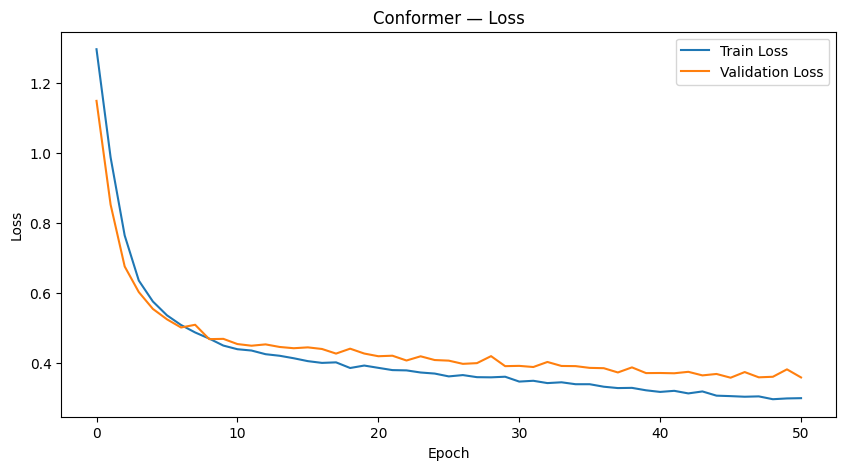

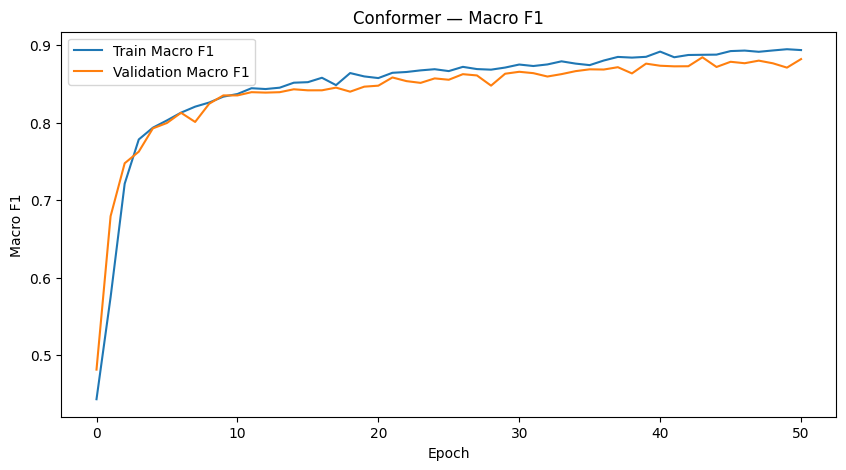

In [ ]:
plt.figure(figsize=(10, 5))
plt.plot(
    history["train_loss"],
    label="Train Loss",
)
plt.plot(
    history["val_loss"],
    label="Validation Loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Conformer — Loss")
plt.legend()
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(
    history["train_f1"],
    label="Train Macro F1",
)
plt.plot(
    history["val_f1"],
    label="Validation Macro F1",
)
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.title("Conformer — Macro F1")
plt.legend()
plt.show()


## 8. Evaluation

In [ ]:
test_loss, test_acc, test_f1, y_true, y_pred = run_epoch(
    model,
    test_loader,
    criterion,
    device,
)

test_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

test_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0,
)

test_balanced_acc = balanced_accuracy_score(
    y_true,
    y_pred,
)

print("=" * 50)
print("FINAL TEST RESULT — TABULAR CONFORMER")
print("=" * 50)
print(f"Accuracy          : {test_acc:.4f}")
print(f"Macro Precision   : {test_precision:.4f}")
print(f"Macro Recall      : {test_recall:.4f}")
print(f"Macro F1          : {test_f1:.4f}")
print(f"Balanced Accuracy : {test_balanced_acc:.4f}")
print(f"Test Loss         : {test_loss:.4f}")


FINAL TEST RESULT — TABULAR CONFORMER
Accuracy          : 0.8732
Macro Precision   : 0.8713
Macro Recall      : 0.8734
Macro F1          : 0.8710
Balanced Accuracy : 0.8734
Test Loss         : 0.3330


In [ ]:
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=[
            TARGET_NAMES[i]
            for i in range(4)
        ],
        zero_division=0,
    )
)


                            precision    recall  f1-score   support

Sehat / Tidak Ada Indikasi       0.87      0.89      0.88       315
Jantung dan Pembuluh Darah       0.85      0.80      0.83       225
      Spes. Penyakit Dalam       0.92      0.86      0.89       300
           Spes. Paru-Paru       0.84      0.95      0.89       225

                  accuracy                           0.87      1065
                 macro avg       0.87      0.87      0.87      1065
              weighted avg       0.87      0.87      0.87      1065



### Confusion Matrix

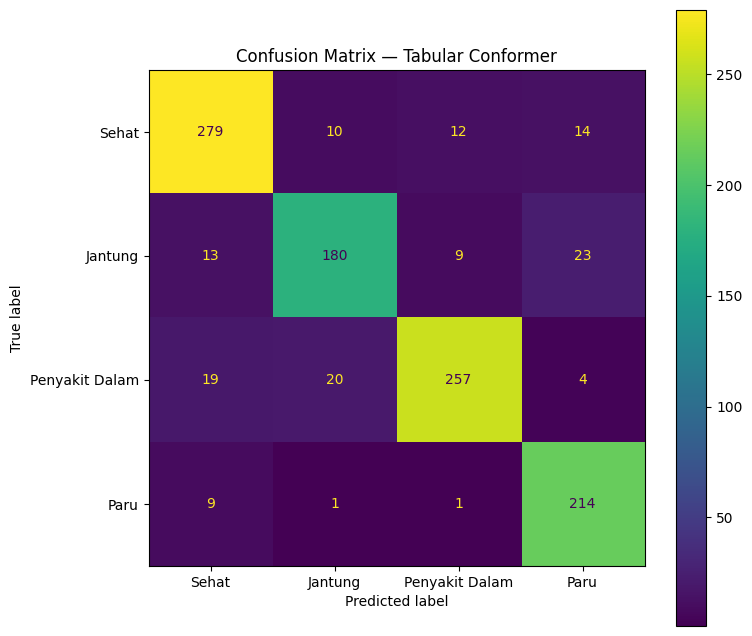

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
)

fig, ax = plt.subplots(
    figsize=(8, 8)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[
        "Sehat",
        "Jantung",
        "Penyakit Dalam",
        "Paru",
    ],
)

disp.plot(
    ax=ax,
    values_format="d",
)

plt.title(
    "Confusion Matrix — Tabular Conformer"
)
plt.show()


## 9. Single Patient Prediction

In [ ]:
model.eval()

sample_idx = 0

sample = X_test_scaled[sample_idx]
sample_tensor = torch.tensor(
    sample,
    dtype=torch.float32,
).unsqueeze(0).to(device)

with torch.no_grad():
    logits = model(sample_tensor)
    probabilities = torch.softmax(
        logits,
        dim=1,
    )[0].cpu().numpy()

prediction = int(
    probabilities.argmax()
)

print("Predicted class:")
print(
    f"{prediction} — "
    f"{TARGET_NAMES[prediction]}"
)

print("\nProbabilities:")
for class_id, prob in enumerate(probabilities):
    print(
        f"{class_id} — "
        f"{TARGET_NAMES[class_id]}: "
        f"{prob:.4f}"
    )


Predicted class:
3 — Spes. Paru-Paru

Probabilities:
0 — Sehat / Tidak Ada Indikasi: 0.0171
1 — Jantung dan Pembuluh Darah: 0.0040
2 — Spes. Penyakit Dalam: 0.0035
3 — Spes. Paru-Paru: 0.9755


## NOTE: Prototype Checkpoint

Jika notebook sampai sini tanpa `NaN` dan menghasilkan:

```text
[✓] Dataset terbaca
[✓] Target 4 kelas
[✓] Split stratified
[✓] Scaling train-only
[✓] Feature tokens terbentuk
[✓] Forward pass
[✓] Training
[✓] Validation
[✓] Test prediction
[✓] Classification report
[✓] Confusion matrix
```

maka prototype Conformer sudah **feasible untuk dilanjutkan**.

Tahap berikutnya baru kita evaluasi apakah representasi/tokenization dan arsitektur Conformer ini perlu dibandingkan dengan Random Forest/XGBoost, bukan langsung melakukan tuning besar.